In [ ]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import blockdynamicnetworks as bdn

# Cargar la red Karate Club
G_nx = nx.karate_club_graph()

print("Número de nodos:", G_nx.number_of_nodes())
print("Número de aristas:", G_nx.number_of_edges())
print("¿Es dirigida?:", nx.is_directed(G_nx))

Número de nodos: 34
Número de aristas: 78
¿Es dirigida?: False


: 

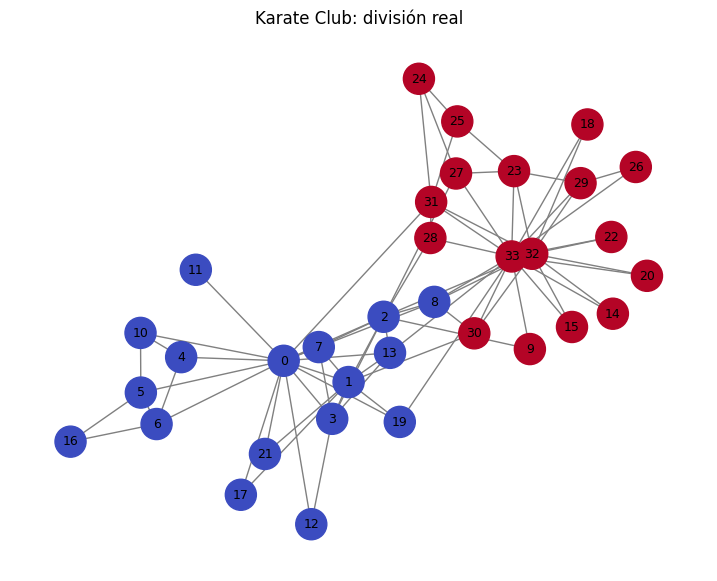

In [2]:
# División real de los clubes
club_real = [
    0 if G_nx.nodes[i]["club"] == "Mr. Hi" else 1
    for i in G_nx.nodes()
]

# Layout
pos = nx.spring_layout(G_nx, seed=123)

plt.figure(figsize=(9, 7))

nx.draw_networkx(
    G_nx,
    pos,
    node_color=club_real,
    cmap="coolwarm",
    with_labels=True,
    node_size=500,
    font_size=9,
    edge_color="gray"
)

plt.title("Karate Club: división real")
plt.axis("off")
plt.show()

In [3]:
def networkx_to_graph(G_nx):
    nodes = list(G_nx.nodes())
    node_to_index = {node: i for i, node in enumerate(nodes)}

    G = bdn.Graph(len(nodes))

    for u, v in G_nx.edges():
        G.add_edge(node_to_index[u], node_to_index[v])

    return G, nodes, node_to_index


G, nodes, node_to_index = networkx_to_graph(G_nx)

print("Nodos en bdn:", G.size())
print("Aristas en bdn:", G.number_of_edges())

Nodos en bdn: 34
Aristas en bdn: 78


In [34]:
import numpy as np
from scipy.optimize import brentq

n = G.size()

def expected_K(alpha, n):
    return sum(alpha / (alpha + i - 1) for i in range(1, n + 1))

alpha = brentq(lambda a: expected_K(a, n) - 2, 1e-6, 100)

print("Alpha:", alpha)
print("E[K]:", expected_K(alpha, n))

Alpha: 0.26844521558887935
E[K]: 2.0000000000001923


In [47]:
# 1. Partición inicial: una sola comunidad
#z0 = bdn.Partition([0] * G.size())

# Obtener la partición real del Karate Club
z_real = [
    0 if G_nx.nodes[i]["club"] == "Mr. Hi" else 1
    for i in G_nx.nodes()
]

# Crear la partición inicial
z0 = bdn.Partition(z_real)

# 2. Prior
prior = bdn.PartitionPrior(0.26844521558887935)

# 3. Modelo posterior
model = bdn.PosteriorModel(
    G,
    prior,
    1.0,
    1.0
)

# 4. Sampler Split-Merge
sampler = bdn.SplitMergeSampler(
    model,
    iterations=1_000_000,
    burn_in=100_000,
    thinning=900,
    seed=12
)

# 5. Inferencia
sampler.run(z0)

# 6. Resultados
samples = sampler.samples()
k_trace = sampler.number_of_communities()
z_final = sampler.final_partition()

print("Muestras guardadas:", len(samples))
print("Comunidades finales:", z_final.number_of_communities())
print("Partición final:", z_final.labels())

print("Splits aceptados:", sampler.accepted_splits())
print("Merges aceptados:", sampler.accepted_merges())

results = sampler.results()
print("Tasa aceptación splits:", results.split_acceptance_rate)
print("Tasa aceptación merges:", results.merge_acceptance_rate)
print("ESS de K:", results.ess_k)
print("ESS log-posterior:", results.ess_log_posterior)

Muestras guardadas: 1000
Comunidades finales: 5
Partición final: [0, 0, 0, 0, 1, 1, 1, 1, 2, 2, 1, 1, 1, 1, 2, 2, 1, 1, 2, 1, 2, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 3, 4]
Splits aceptados: 5872
Merges aceptados: 5869
Tasa aceptación splits: 0.01723616659670834
Tasa aceptación merges: 0.008901582082172416
ESS de K: 1595.4422373924297
ESS log-posterior: 747.3724513211072


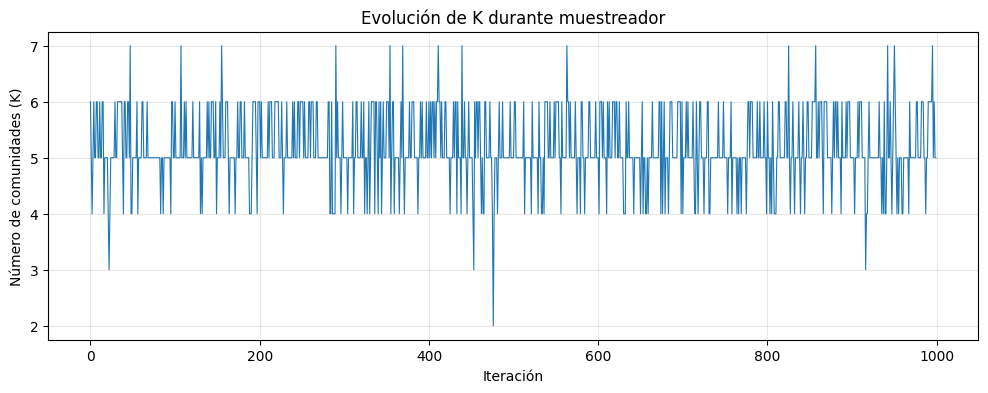

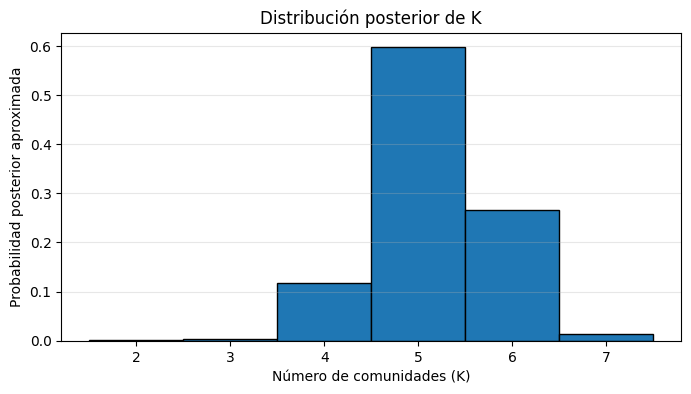

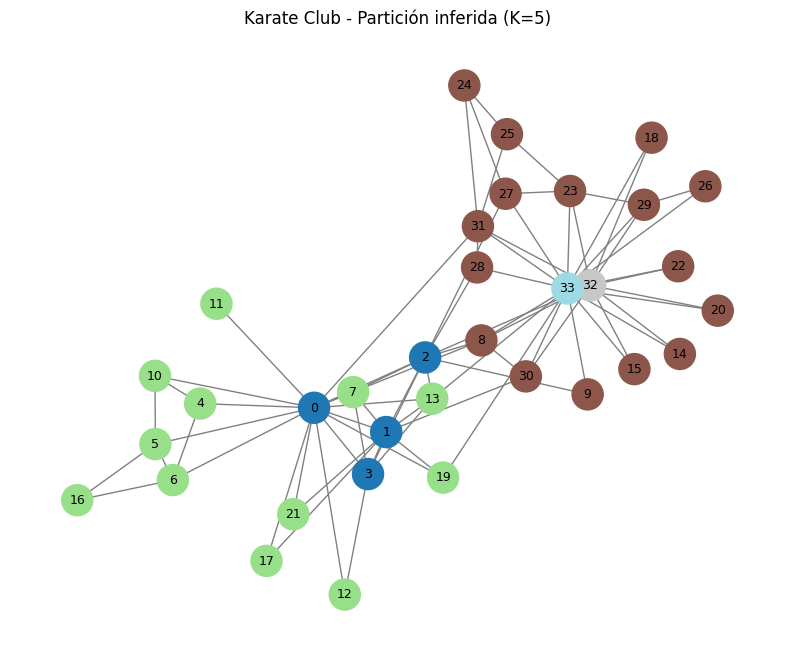

In [48]:
plt.figure(figsize=(12, 4))

plt.plot(k_trace, linewidth=0.8)
plt.xlabel("Iteración")
plt.ylabel("Número de comunidades (K)")
plt.title("Evolución de K durante muestreador")
plt.grid(alpha=0.3)

plt.show()

K_samples = [
    s.number_of_communities()
    for s in samples
]

plt.figure(figsize=(8, 4))

bins = np.arange(min(K_samples) - 0.5,
                 max(K_samples) + 1.5, 1)

plt.hist(K_samples, bins=bins, density=True, edgecolor="black")

plt.xlabel("Número de comunidades (K)")
plt.ylabel("Probabilidad posterior aproximada")
plt.title("Distribución posterior de K")
plt.xticks(range(min(K_samples), max(K_samples) + 1))
plt.grid(axis="y", alpha=0.3)

plt.show()

z_inferred = np.array(z_final.labels())

plt.figure(figsize=(10, 8))

nx.draw_networkx(
    G_nx,
    pos,
    node_color=z_inferred,
    cmap="tab20",
    with_labels=True,
    node_size=500,
    font_size=9,
    edge_color="gray"
)

plt.title(
    f"Karate Club - Partición inferida (K={z_final.number_of_communities()})"
)

plt.axis("off")
plt.show()




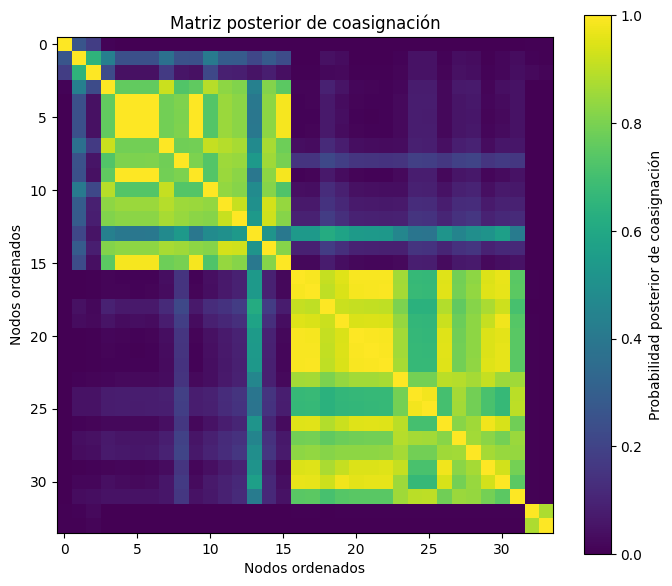

In [49]:
# Obtener etiquetas de cada muestra
sample_labels = np.array([
    s.labels() for s in samples
])

# Matriz de coasignación
n = G.size()
coassignment = np.zeros((n, n))

for z in sample_labels:
    coassignment += (z[:, None] == z[None, :])

coassignment /= len(sample_labels)

# Ordenar nodos según la partición inferida
order = np.argsort(z_inferred)
coassignment_ordered = coassignment[np.ix_(order, order)]

# Visualización
plt.figure(figsize=(8, 7))

plt.imshow(
    coassignment_ordered,
    cmap="viridis",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Probabilidad posterior de coasignación")
plt.xlabel("Nodos ordenados")
plt.ylabel("Nodos ordenados")
plt.title("Matriz posterior de coasignación")

plt.show()

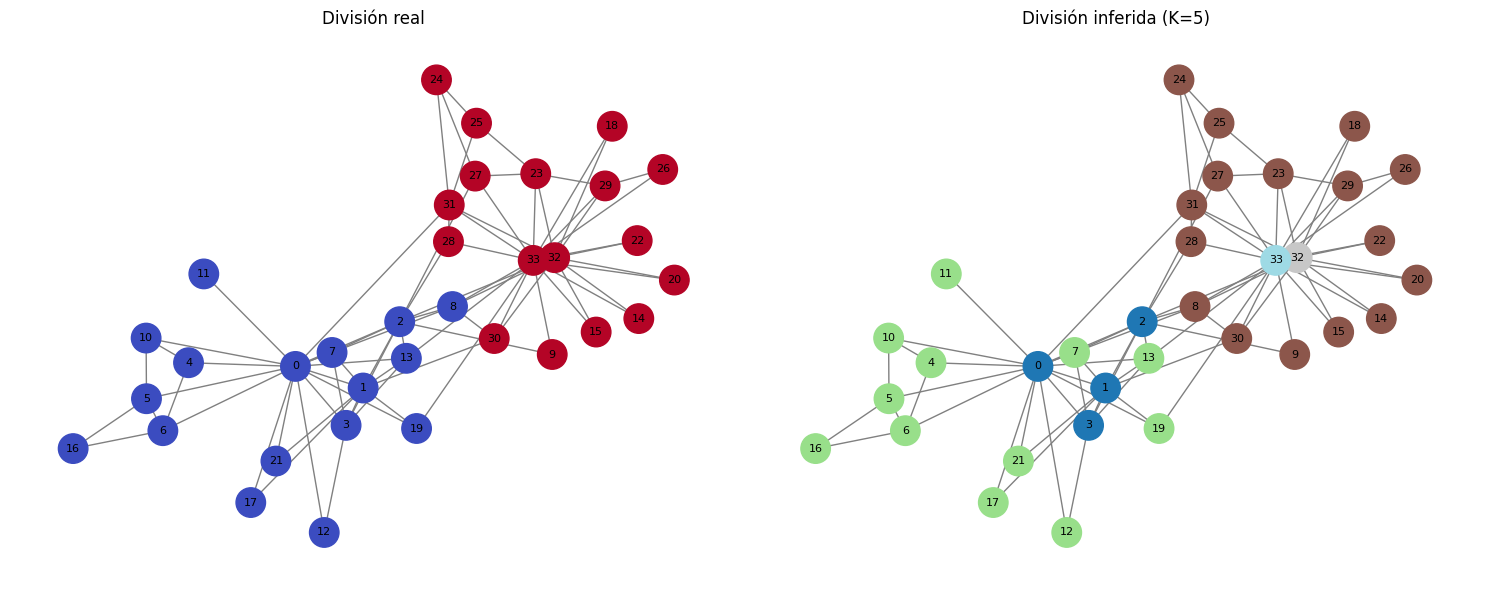

In [50]:
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# División real
nx.draw_networkx(
    G_nx,
    pos,
    node_color=club_real,
    cmap="coolwarm",
    with_labels=True,
    node_size=450,
    font_size=8,
    edge_color="gray",
    ax=axes[0]
)

axes[0].set_title("División real")
axes[0].axis("off")

# División inferida
nx.draw_networkx(
    G_nx,
    pos,
    node_color=z_inferred,
    cmap="tab20",
    with_labels=True,
    node_size=450,
    font_size=8,
    edge_color="gray",
    ax=axes[1]
)

axes[1].set_title(
    f"División inferida (K={z_final.number_of_communities()})"
)
axes[1].axis("off")

plt.tight_layout()
plt.show()

In [51]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score

# Partición real
club_real = np.array([
    0 if G_nx.nodes[i]["club"] == "Mr. Hi" else 1
    for i in G_nx.nodes()
])

# Calcular ARI para cada muestra posterior
ari_samples = np.array([
    adjusted_rand_score(club_real, s.labels())
    for s in samples
])

# ARI de la partición final
ari_final = adjusted_rand_score(
    club_real,
    z_final.labels()
)

print("ARI de la partición final:", ari_final)
print("ARI posterior promedio:", ari_samples.mean())
print("ARI posterior mediano:", np.median(ari_samples))
print("Desviación estándar:", ari_samples.std())
print("ARI mínimo:", ari_samples.min())
print("ARI máximo:", ari_samples.max())

ARI de la partición final: 0.6040575916230366
ARI posterior promedio: 0.46906765432567693
ARI posterior mediano: 0.4948609240868541
Desviación estándar: 0.15882630830126454
ARI mínimo: -0.015052356020942409
ARI máximo: 0.7808860346141286


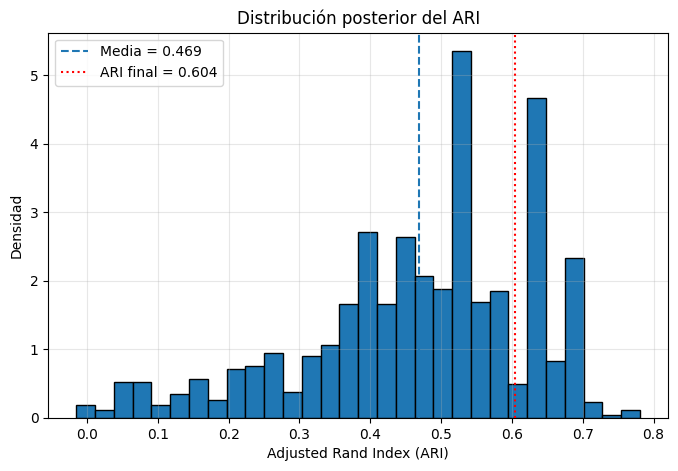

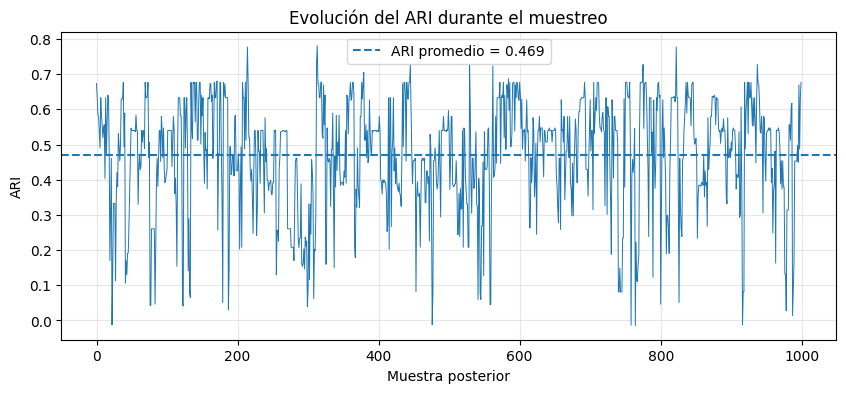

In [53]:
plt.figure(figsize=(8, 5))

plt.hist(
    ari_samples,
    bins=30,
    density=True,
    edgecolor="black"
)

plt.axvline(
    ari_samples.mean(),
    linestyle="--",
    label=f"Media = {ari_samples.mean():.3f}"
)

plt.axvline(
    ari_final,
    color="red",
    linestyle=":",
    label=f"ARI final = {ari_final:.3f}"
)

plt.xlabel("Adjusted Rand Index (ARI)")
plt.ylabel("Densidad")
plt.title("Distribución posterior del ARI")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

plt.figure(figsize=(10, 4))

plt.plot(ari_samples, linewidth=0.7)

plt.axhline(
    ari_samples.mean(),
    linestyle="--",
    label=f"ARI promedio = {ari_samples.mean():.3f}"
)

plt.xlabel("Muestra posterior")
plt.ylabel("ARI")
plt.title("Evolución del ARI durante el muestreo")
plt.legend()
plt.grid(alpha=0.3)

plt.show()